# Entrega final — Fase 3: auditoría del STN y dictamen sobre la profundidad
**Proyecto integrador · Deep Learning · PM2.5 horario, estación Fontibón (Bogotá)**

Este cuaderno consolida todo lo que pide la Entrega final y **cierra las tres correcciones de la Fase 2**:

| Corrección del profesor (Fase 2) | Dónde se resuelve aquí |
|---|---|
| Decidir la arquitectura **antes** de buscar hiperparámetros, para que el checkpoint de Beijing encaje | §3: una sola arquitectura (d_model=128, d_ff=256) preentrenada en Beijing y usada en Bogotá; se reporta cuántos tensores se cargan realmente |
| Al menos **tres semillas** por configuración | §5: `SEMILLAS` (por defecto 3; subir a 5 si hay tiempo) y comparación pareada con bootstrap por bloques |
| Resolver los **dos conteos** (8 547 vs 8 523) | §1: protocolo común con 24 h de contexto; todos los modelos se evalúan sobre las mismas horas |
| Brecha con el artículo sin hipótesis | §2: hipótesis comprobable sobre la varianza del conjunto de prueba |
| Comparación con el LSTM sobre conjuntos distintos | §4: persistencia, Ridge, Random Forest y LSTM sobre **las mismas ventanas y las mismas horas** |

Después vienen los núcleos de la Entrega final: auditoría con explicabilidad (§7), análisis de fallas y calibración (§8) y la tabla de evidencia para el dictamen (§9).

**Todo se guarda en `resultados_final/`** (JSON, NPZ, PNG). Cada corrida es *reanudable*: si el JSON ya existe, se salta. Al final (§10) se genera `resumen_entrega_final.json`, que es lo que hay que compartir para redactar el informe.

## §0. Entorno y configuración

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import sys, json, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Los módulos final_data.py y final_stn.py deben estar junto a este cuaderno.
sys.path.insert(0, str(Path.cwd()))
from final_data import *
import final_stn as S
import torch
from final_stn import DEVICE

def localizar(nombre):
    cwd = Path.cwd().resolve()
    for base in [cwd, *cwd.parents]:
        for sub in ["", "modelos y bd", "metadatos", "data", "Proyecto---Deep-Learning/modelos y bd", "Proyecto---Deep-Learning/metadatos"]:
            p = base / sub / nombre
            if p.is_file(): return p
    raise FileNotFoundError(nombre)

RUTA_BJ  = localizar("PRSA_data_2010.1.1-2014.12.31.csv")
RUTA_BOG = localizar("bogota_calidad_aire_raw.parquet")
OUT = Path("resultados_final_enmascarado"); (OUT/"modelos").mkdir(parents=True, exist_ok=True); (OUT/"figuras").mkdir(exist_ok=True)

# ── Protocolo (fijo para TODOS los modelos) ──
ESTACION, TEST_BOG, TEST_BJ = "FONTIBÓN", "2024-01-01", "2014-01-01"
SEQ, LABEL, PRED = 24, 12, 1

# ── Arquitectura DECIDIDA ANTES de buscar nada más (corrección del profesor) ──
# Es la mejor de la búsqueda de la Fase 2 (val MSE 0.01233). Se usa idéntica en Beijing (fuente) y Bogotá (destino).
CFG = dict(d_model=128, n_heads=8, d_ff=256, dropout=0.05, factor=5, e_layers=3, d_layers=2,
           seq_len=SEQ, label_len=LABEL)

# ── Entrenamiento ──
BATCH, EPOCAS, PACIENCIA = 64, 40, 6
LR_NUEVO, LR_CUERPO = 1e-4, 1e-5      # LR_NUEVO: pesos sin preentrenar (igual que scratch); LR_CUERPO: cuerpo de Beijing al afinar
SEMILLAS = [0, 1, 2]                   # subir a [0,1,2,3,4] si hay tiempo de cómputo
REGIMENES = ["scratch", "frozen", "ft_partial", "ft_full"]

print("PyTorch", torch.__version__, "| dispositivo:", DEVICE)
print("Beijing:", RUTA_BJ.name, "| Bogotá:", RUTA_BOG.name)

PyTorch 2.11.0+cu128 | dispositivo: cuda
Beijing: PRSA_data_2010.1.1-2014.12.31.csv | Bogotá: bogota_calidad_aire_raw.parquet


In [2]:
import torch
print(torch.__version__, "| CUDA de torch:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("capacidad de cómputo:", torch.cuda.get_device_capability(0))
print("arquitecturas incluidas en este PyTorch:", torch.cuda.get_arch_list())

2.11.0+cu128 | CUDA de torch: 12.8
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
capacidad de cómputo: (12, 0)
arquitecturas incluidas en este PyTorch: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


In [3]:
### Prevención


import torch, final_stn as S
print(torch.__version__, "| CUDA de torch:", torch.version.cuda, "| GPU:", torch.cuda.is_available())

# 1) GPU básica
x = torch.randn(1000, 1000, device=S.DEVICE); print("matmul:", (x @ x).sum().item())

# 2) modelo, forward pequeño
m = S.construir_modelo(9, CFG, 1)
e = torch.randn(8, 24, 9, device=S.DEVICE); d = torch.randn(8, 13, 9, device=S.DEVICE)
print("forward:", m(e, d).shape)

# 3) un paso de entrenamiento con lote 64
m.train(); e = torch.randn(64, 24, 9, device=S.DEVICE); d = torch.randn(64, 13, 9, device=S.DEVICE)
m(e, d).pow(2).mean().backward(); print("backward OK")

2.11.0+cu128 | CUDA de torch: 12.8 | GPU: True
matmul: -26859.54296875
forward: torch.Size([8, 1, 1])
backward OK


## §1. Datos y protocolo común de evaluación (resuelve 8 547 vs 8 523)

**Diagnóstico.** En la réplica, `WindowDataset` solo genera objetivos a partir del índice `seq_len` del tramo de prueba: las **primeras 24 h de 2024 nunca eran objetivo** porque no tenían contexto. De ahí 8 547 − 24 = 8 523. Las líneas base de la Fase 1 usaban otros criterios de elegibilidad (secuencias sin NaN → 7 039; persistencia con la hora previa observada → 8 479), así que *cada modelo se evaluaba sobre un conjunto distinto*.

**Solución.** `prepare_v2` antepone a val y test las 24 h finales del tramo anterior (contexto causal: solo pasado). Así toda hora de 2024 es objetivo y **todos los modelos se evalúan sobre las mismas horas con PM2.5 observado**. La celda siguiente lo verifica con una aserción.

In [4]:
df_bj  = load_beijing(RUTA_BJ)
df_bog = load_bogota(RUTA_BOG, estacion=ESTACION)

d_bog = prepare_v2(df_bog, "PM2.5", TEST_BOG, seq_len=SEQ)
d_bj  = prepare_v2(df_bj,  "pm2.5", TEST_BJ,  seq_len=SEQ)

# ── Reconciliación de conteos (Bogotá, 2024) ──
obs = d_bog.obs_test
primeras24 = int(obs[:24].sum())
cuadro = pd.DataFrame({"concepto": [
    "Horas de 2024 en la serie", "Horas con PM2.5 observado (= conjunto común de evaluación)",
    "…de ellas, en las primeras 24 h (sin contexto en la réplica)", "Conteo de la réplica (observadas − primeras 24 h observadas)",
    "Conteo de la Fase 1 (RF/LSTM con MissForest)", "Conteo de la persistencia en la Fase 1 (hora previa observada)",
    "Conteo de LSTM/RF 'control' sin imputar (secuencias completas)"],
    "n": [len(obs), int(obs.sum()), primeras24, int(obs.sum()) - primeras24, 8547, 8479, 7039]})
display(cuadro)
if (int(obs.sum()) - primeras24) == 8523:
    print("OK: 8547 - 24 = 8523 → la diferencia eran las primeras 24 h de 2024 (sin ventana). Ahora se evalúan todas.")
else:
    print("AVISO: la hipótesis de las 24 h NO reproduce 8523 con estos datos; revisar el parquet usado.")

# ── Ventanas (tensores) ──
def a_dev(t): return tuple(torch.tensor(x, device=DEVICE) for x in t)

mask_bog = {
    "train": d_bog.obs_train,
    "val": np.r_[d_bog.obs_train[-SEQ:], d_bog.obs_val],
    "test": np.r_[d_bog.obs_val[-SEQ:], d_bog.obs_test],
}
mask_bj = {
    "train": d_bj.obs_train,
    "val": np.r_[d_bj.obs_train[-SEQ:], d_bj.obs_val],
    "test": np.r_[d_bj.obs_val[-SEQ:], d_bj.obs_test],
}
W_bog = {k: make_windows(a, SEQ, LABEL, PRED, d_bog.target_idx, mask_bog[k]) for k, a in
         [("train", d_bog.train), ("val", d_bog.val_ctx), ("test", d_bog.test_ctx)]}
W_bj  = {k: make_windows(a, SEQ, LABEL, PRED, d_bj.target_idx, mask_bj[k]) for k, a in
         [("train", d_bj.train), ("val", d_bj.val_ctx), ("test", d_bj.test_ctx)]}
assert len(W_bog["test"][0]) == len(d_bog.obs_test) and len(W_bog["val"][0]) == len(d_bog.obs_val)
assert np.array_equal(W_bog["test"][3][:, 0, 0], d_bog.obs_test)
assert np.array_equal(W_bog["val"][3][:, 0, 0], d_bog.obs_val)
assert int(d_bog.obs_test.sum()) == 8547, f"Esperadas 8.547 horas observadas, llegaron {int(d_bog.obs_test.sum())}"
assert d_bog.test_index.is_monotonic_increasing and d_bog.test_index.is_unique
T_bog = {k: a_dev(v) for k, v in W_bog.items()}
T_bj  = {k: a_dev(v) for k, v in W_bj.items()}

y_test = d_bog.inverse_target(W_bog["test"][2][:, 0, 0]); y_val = d_bog.inverse_target(W_bog["val"][2][:, 0, 0])
print({k: v[0].shape for k, v in W_bog.items()}, "| F =", d_bog.train.shape[1], "variables")
print("Cobertura de PM2.5 observado en test:", f"{d_bog.obs_test.mean():.1%}")

,concepto,n
0,Horas de 2024 en la serie,8784
1,Horas con PM2.5 observado (= conjunto común de...,8547
2,"…de ellas, en las primeras 24 h (sin contexto ...",24
3,Conteo de la réplica (observadas − primeras 24...,8523
4,Conteo de la Fase 1 (RF/LSTM con MissForest),8547
5,Conteo de la persistencia en la Fase 1 (hora p...,8479
6,Conteo de LSTM/RF 'control' sin imputar (secue...,7039


OK: 8547 - 24 = 8523 → la diferencia eran las primeras 24 h de 2024 (sin ventana). Ahora se evalúan todas.
{'train': (31534, 24, 9), 'val': (3506, 24, 9), 'test': (8784, 24, 9)} | F = 9 variables
Cobertura de PM2.5 observado en test: 97.3%


## §2. Réplica: por qué RMSE/MAE del artículo no son comparables (hipótesis comprobable)

Hipótesis: **el conjunto de prueba del artículo no tiene la misma varianza que el 2014 del archivo público**. Con $R^2 = 1 - \mathrm{MSE}/\mathrm{Var}(y)$ se puede despejar la varianza implícita de cada resultado. Si la del artículo (≈ 76 µg/m³ de desviación) no coincide con la de cualquier partición posible del archivo público, la brecha de RMSE/MAE **no es atribuible al modelo**.

In [5]:
def var_implicita(rmse, r2): return np.sqrt(rmse**2 / (1 - r2))

y_bj = df_bj["pm2.5"]
tabla = pd.DataFrame({
    "fuente": ["Artículo (STN, h1)", "Nuestra réplica (STN-512)", "Nuestra persistencia"],
    "RMSE": [19.04, 22.212, 22.152], "R2": [0.937, 0.9437, 0.9440]})
tabla["desv_est_implícita_test"] = [var_implicita(r, q) for r, q in zip(tabla.RMSE, tabla.R2)]
tabla["RMSE/desv (adimensional)"] = tabla.RMSE / tabla["desv_est_implícita_test"]
display(tabla.round(3))

cand = {"2014 completo": y_bj["2014"], "últimos 20% cronol.": y_bj.iloc[int(len(y_bj)*.8):],
        "últimos 10% cronol.": y_bj.iloc[int(len(y_bj)*.9):], "2013-2014": y_bj["2013":"2014"],
        "20% aleatorio": y_bj.dropna().sample(frac=.2, random_state=0), "serie completa": y_bj}
display(pd.DataFrame({k: {"n": int(v.notna().sum()), "desv_est": round(float(v.std()), 1)} for k, v in cand.items()}).T)
print("Artículo implica ≈ 75.9; ninguna partición del archivo público baja de ≈ 89.")

,fuente,RMSE,R2,desv_est_implícita_test,RMSE/desv (adimensional)
0,"Artículo (STN, h1)",19.040,0.937,75.857,0.251
1,Nuestra réplica (STN-512),22.212,0.944,93.612,0.237
2,Nuestra persistencia,22.152,0.944,93.609,0.237


,n,desv_est
2014 completo,8661.0,93.5
últimos 20% cronol.,8666.0,93.5
últimos 10% cronol.,4317.0,89.1
2013-2014,17339.0,95.8
20% aleatorio,8351.0,90.9
serie completa,41757.0,92.1


Artículo implica ≈ 75.9; ninguna partición del archivo público baja de ≈ 89.


## §3. Arquitectura fija y preentrenamiento en Beijing (fuente de la transferencia)
Se entrena **la misma arquitectura** (≈1.2 M parámetros) en Beijing con el protocolo del artículo (train 2010–2013 / test 2014). Es una *versión reducida justificada* del STN-512 de la réplica; el resultado del STN-512 (R² 0.9437, 26.6 M parámetros, 23 épocas) se mantiene como evidencia de réplica fiel. Solo cambian de forma las capas de entrada (11 variables en Beijing, 9 en Bogotá); todo lo demás es compatible.

### Comparación configuración por configuración: artículo vs. réplica Beijing

| Elemento | Zhang & Zhang (2023) | Réplica de esta entrega | Estado |
|---|---|---|---|
| Tarea | Pronóstico PM2.5 h1 y horizontes 6, 12, 24 y 48 h | Pronóstico h1 | Coincide para h1; no se replican los horizontes largos |
| Datos Beijing | 2010–2014; entrenamiento primeros 4 años y prueba 2014 | Mismo CSV público y corte 2014; validación cronológica del 10 % final del periodo de entrenamiento | Parcial: la validación del artículo es aleatoria 10 % del train |
| Ventana de entrada | 24 horas | 24 horas | Coincide |
| Variables | 8 variables originales: PM2.5, DEWP, TEMP, PRES, cbwd, Iws, Is, Ir | 11 columnas tras one-hot de cbwd (4 direcciones/estados) | Representación equivalente, dimensionalidad distinta por codificación |
| Encoder/decoder | STN de dos ramas; 3 encoders y 2 decoders | Dos ramas paralelas implementadas; 3 capas en una rama y 2 en otra; 2 capas decoder | Coincide parcialmente; documentar el detalle de las ramas y su longitud |
| Atención | Multi-head sparse attention en encoder y decoder; atención multi-head estándar cruzada en decoder | ProbAttention dispersa en encoder y self-attention en decoder + FullAttention cruzada | Coincide en el diseño general |
| d_model / cabezas / d_ff | No especificados explícitamente en el texto del artículo | d_model=128, 8 cabezas, d_ff=256 | No verificable; configuración elegida por recursos |
| Optimizador | Adam | Adam | Coincide |
| Learning rate inicial | 1e-4 | 1e-4 en preentrenamiento Beijing | Coincide |
| Batch size | 32 | 64 | Difiere |
| Épocas máximas | 200 | 40 | Difiere por límite de cómputo |
| Pérdida | MSE | MSE enmascarada: solo objetivos PM2.5 observados | Adaptación metodológica necesaria por faltantes |
| Normalización | [0,1] | MinMax ajustado solo con train | Coincide en rango; difiere en el ajuste sin fuga |
| Faltantes | Eliminación de outliers e interpolación lineal | Imputación causal ffill hasta 24 h y mediana train; imputados solo como entradas, no como etiquetas | Difiere deliberadamente |
| Semillas | No reportadas como repetición multisemilla | Beijing semilla 0; Bogotá semillas 0,1,2 | Diferencia para reproducibilidad/variabilidad |

**Lectura:** la réplica conserva la ventana, el optimizador, la tasa inicial, la profundidad declarada de encoder/decoder y la idea de atención dispersa. No es una reproducción idéntica del protocolo: usa batch y tope de épocas distintos, validación cronológica en lugar de aleatoria y una política causal de faltantes. El artículo no publica valores explícitos para `d_model`, número de cabezas ni `d_ff`; no se deben inventar ni afirmar como coincidencias. La versión de 128 dimensiones es una réplica computacional reducida, no el tamaño original verificable.

Fuente: Zhang, Z. & Zhang, S. (2023), DOI: 10.1007/s13762-023-04900-1.


In [6]:
def correr(nombre, W, T, data, regimen, semilla, estado_fuente=None, cfg=CFG, es_lstm=False, lr_new=LR_NUEVO):
    ruta_json = OUT / f"{nombre}_s{semilla}.json"
    if ruta_json.exists():
        return json.loads(ruta_json.read_text())
    S.set_seed(semilla)
    nf = data.train.shape[1]
    if es_lstm:
        model = S.LSTMBase(nf).to(DEVICE); fwd = S.fwd_lstm
        nuevos, cuerpo = list(model.parameters()), []
        info = {"regimen": "lstm", "params_totales": int(sum(p.numel() for p in model.parameters())),
                "params_entrenables": int(sum(p.numel() for p in model.parameters()))}
    else:
        model = S.construir_modelo(nf, cfg, PRED); fwd = S.fwd_stn
        nuevos, cuerpo, info = S.aplicar_regimen(model, regimen, estado_fuente)
    print(f"[{nombre} s{semilla}] entrenables={info['params_entrenables']:,}" +
          (f" | tensores cargados {info['tensores_cargados']}/{info['tensores_modelo']}" if 'tensores_cargados' in info else ""))
    hist, mejor_ep, seg = S.fit(model, nuevos, cuerpo, T["train"], T["val"], fwd, lr_new, LR_CUERPO,
                                EPOCAS, PACIENCIA, BATCH, semilla, log=lambda s: None)
    S.sync(); t0 = time.perf_counter()
    p_te = S.predecir(model, T["test"][0], T["test"][1], fwd)
    S.sync(); t_inf = time.perf_counter() - t0
    p_va = S.predecir(model, T["val"][0], T["val"][1], fwd)
    inv = data.inverse_target
    pt, pv = inv(p_te), inv(p_va)
    yt, yv = inv(T["test"][2][:, 0, 0].cpu().numpy()), inv(T["val"][2][:, 0, 0].cpu().numpy())
    m = metricas(yt[data.obs_test], pt[data.obs_test])
    # Guardar timestamps para demostrar identidad exacta del conjunto evaluado.
    eval_index = data.test_index[data.obs_test]
    res = {"nombre": nombre, "semilla": semilla, **m, "mejor_epoca": mejor_ep, "epocas": len(hist),
           "seg_entrenamiento": round(seg, 1), "seg_inferencia_test": round(t_inf, 3),
           "loss_masking": True, "mask_protocol": "observed_targets_only_v1",
           "info": info, "historia": hist}
    np.savez_compressed(OUT / f"{nombre}_s{semilla}_preds.npz", pred_test=pt, true_test=yt, obs_test=data.obs_test,
                        pred_val=pv, true_val=yv, obs_val=data.obs_val,
                        test_timestamps=data.test_index.astype("datetime64[ns]").astype(str),
                        val_timestamps=data.val_index.astype("datetime64[ns]").astype(str))
    if not es_lstm: torch.save(model.state_dict(), OUT / "modelos" / f"{nombre}_s{semilla}.pt")
    ruta_json.write_text(json.dumps(res, indent=1, ensure_ascii=False))
    print(f"   RMSE={m['RMSE']:.3f} MAE={m['MAE']:.3f} R2={m['R2']:.4f} n={m['n']} | mejor ép {mejor_ep}/{len(hist)} | {seg:.0f}s")
    return res

# Preentrenamiento Beijing (semilla 0). n_eval aquí = horas de 2014 con PM2.5 observado.
res_bj = correr("beijing128", W_bj, T_bj, d_bj, "scratch", 0)
ckpt_bj = OUT / "modelos" / "beijing128_s0.pt"
pers_bj = d_bj.inverse_target(W_bj["test"][0][:, -1, d_bj.target_idx])
yt_bj = d_bj.inverse_target(W_bj["test"][2][:, 0, 0])
m_pers_bj = metricas(yt_bj[d_bj.obs_test], pers_bj[d_bj.obs_test])
print("Beijing-128   :", {k: round(res_bj[k], 4) for k in ("RMSE", "MAE", "R2", "n")})
print("Persistencia  :", {k: round(v, 4) for k, v in m_pers_bj.items()})
print("Artículo      : RMSE 19.04 MAE 11.13 R2 0.937 | STN-512 réplica: RMSE 22.212 MAE 12.935 R2 0.9437")

[beijing128 s0] entrenables=1,217,921 | tensores cargados 0/165
   RMSE=22.775 MAE=14.185 R2=0.9407 n=8661 | mejor ép 25/31 | 667s
Beijing-128   : {'RMSE': 22.7747, 'MAE': 14.185, 'R2': 0.9407, 'n': 8661}
Persistencia  : {'RMSE': 22.1365, 'MAE': 11.959, 'R2': 0.944, 'n': 8661}
Artículo      : RMSE 19.04 MAE 11.13 R2 0.937 | STN-512 réplica: RMSE 22.212 MAE 12.935 R2 0.9437


## §4. Líneas base sobre **las mismas ventanas y las mismas horas**
Persistencia (hora previa imputada causalmente), Ridge (ML I), Random Forest (ML II) y un LSTM mínimo (3+ semillas). Todos ven exactamente los mismos 8 547 objetivos. Esto reemplaza la comparación de la Fase 2, que mezclaba conjuntos.

In [7]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

inv = d_bog.inverse_target
mtr = W_bog["train"][3][:, 0, 0]
Xtr_all = W_bog["train"][0].reshape(len(W_bog["train"][0]), -1)
ytr_all = W_bog["train"][2][:, 0, 0]
Xtr, ytr = Xtr_all[mtr], ytr_all[mtr]
Xte = W_bog["test"][0].reshape(len(W_bog["test"][0]), -1)
Xva = W_bog["val"][0].reshape(len(W_bog["val"][0]), -1)
obs_t, obs_v = d_bog.obs_test, d_bog.obs_val
base = {}
F_T = OUT / "base_tiempos.json"
tiempos = json.loads(F_T.read_text()) if F_T.exists() else {}

def guardar_base(nombre, p_te, p_va, seg_tr, seg_inf):
    np.savez_compressed(OUT / f"{nombre}_s0_preds.npz", pred_test=inv(p_te), true_test=y_test, obs_test=obs_t,
                        pred_val=inv(p_va), true_val=y_val, obs_val=obs_v,
                        test_timestamps=d_bog.test_index.astype("datetime64[ns]").astype(str),
                        val_timestamps=d_bog.val_index.astype("datetime64[ns]").astype(str))
    tiempos[nombre] = [seg_tr, seg_inf]; F_T.write_text(json.dumps(tiempos))

def cargar_base(nombre):
    z = np.load(OUT / f"{nombre}_s0_preds.npz")
    m = metricas(z["true_test"][z["obs_test"]], z["pred_test"][z["obs_test"]])
    base[nombre] = {**m, "seg_entrenamiento": tiempos[nombre][0], "seg_inferencia_test": tiempos[nombre][1]}
    print(nombre, {k: round(v, 4) for k, v in m.items()}, flush=True)

def hecho(n): return (OUT / f"{n}_s0_preds.npz").exists() and n in tiempos

if not hecho("persistencia"):
    t0 = time.perf_counter()
    guardar_base("persistencia", W_bog["test"][0][:, -1, d_bog.target_idx], W_bog["val"][0][:, -1, d_bog.target_idx], 0.0, time.perf_counter() - t0)
cargar_base("persistencia")

if not hecho("ridge"):
    t0 = time.perf_counter(); rid = Ridge(alpha=1.0).fit(Xtr, ytr); s_tr = time.perf_counter() - t0
    t0 = time.perf_counter(); p = rid.predict(Xte); s_in = time.perf_counter() - t0
    guardar_base("ridge", p, rid.predict(Xva), s_tr, s_in)
cargar_base("ridge")

print("entrenando RF…", flush=True)
if not hecho("rf"):
    t0 = time.perf_counter()
    rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.2, n_jobs=2, random_state=0).fit(Xtr, ytr)
    s_tr = time.perf_counter() - t0
    t0 = time.perf_counter(); p = rf.predict(Xte); s_in = time.perf_counter() - t0
    guardar_base("rf", p, rf.predict(Xva), s_tr, s_in); del rf
cargar_base("rf")

persistencia {'RMSE': 6.8314, 'MAE': 4.8121, 'R2': 0.7037, 'n': 8547}
ridge {'RMSE': 5.9243, 'MAE': 4.2394, 'R2': 0.7772, 'n': 8547}
entrenando RF…
rf {'RMSE': 6.9666, 'MAE': 4.7278, 'R2': 0.6919, 'n': 8547}


In [8]:
res_lstm = [correr("lstm", W_bog, T_bog, d_bog, "lstm", s, es_lstm=True, lr_new=1e-3) for s in SEMILLAS]
display(pd.DataFrame(base).T[["RMSE", "MAE", "R2", "n", "seg_entrenamiento", "seg_inferencia_test"]].round(4))

[lstm s0] entrenables=52,545
   RMSE=6.004 MAE=4.279 R2=0.7712 n=8547 | mejor ép 15/21 | 38s
[lstm s1] entrenables=52,545
   RMSE=6.071 MAE=4.293 R2=0.7660 n=8547 | mejor ép 23/29 | 51s
[lstm s2] entrenables=52,545
   RMSE=6.032 MAE=4.285 R2=0.7690 n=8547 | mejor ép 31/37 | 73s


,RMSE,MAE,R2,n,seg_entrenamiento,seg_inferencia_test
persistencia,6.8314,4.8121,0.7037,8547.0,0.0000,0.0000
ridge,5.9243,4.2394,0.7772,8547.0,0.2654,0.0052
rf,6.9666,4.7278,0.6919,8547.0,16.5167,0.1157


## §5. STN en Bogotá: cuatro regímenes × semillas
- `scratch`: todo aleatorio (lr 1e-4).
- `frozen`: cuerpo de Beijing congelado; solo las capas de entrada (extractor congelado).
- `ft_partial`: encoder congelado; decoder + proyección + capas nuevas se afinan (fine-tuning parcial).
- `ft_full`: todo se afina, con lr 1e-5 para el cuerpo y 1e-4 para lo nuevo.

**Control del confusor de la Fase 2:** la tasa de aprendizaje de los pesos *nuevos* es la misma (1e-4) en todos los regímenes, y todos usan el mismo criterio de parada, el mismo batch y las mismas semillas. Solo cambia *qué se inicializa desde Beijing* y *qué se congela*.

In [9]:
estado_bj = torch.load(ckpt_bj, map_location="cpu")
res = {r: [] for r in REGIMENES}
for r in REGIMENES:
    for s in SEMILLAS:
        res[r].append(correr(f"stn_{r}", W_bog, T_bog, d_bog, r, s, estado_fuente=estado_bj))

info_r = {r: res[r][0]["info"] for r in REGIMENES}
display(pd.DataFrame({r: {"tensores cargados": f"{i.get('tensores_cargados', 0)}/{i['tensores_modelo']}",
                          "params cargados": i.get("params_cargados", 0), "params entrenables": i["params_entrenables"],
                          "tensores NO cargados": len(i["no_cargados"])} for r, i in info_r.items()}).T)
print("Tensores que no encajan (deben ser solo las capas de entrada):", info_r["frozen"]["no_cargados"])

[stn_scratch s0] entrenables=1,216,385 | tensores cargados 0/165
   RMSE=6.042 MAE=4.234 R2=0.7682 n=8547 | mejor ép 15/21 | 485s
[stn_scratch s1] entrenables=1,216,385 | tensores cargados 0/165
   RMSE=6.129 MAE=4.298 R2=0.7615 n=8547 | mejor ép 16/22 | 526s
[stn_scratch s2] entrenables=1,216,385 | tensores cargados 0/165
   RMSE=6.093 MAE=4.275 R2=0.7643 n=8547 | mejor ép 18/24 | 534s
[stn_frozen s0] entrenables=6,912 | tensores cargados 163/165
   RMSE=6.029 MAE=4.331 R2=0.7692 n=8547 | mejor ép 39/40 | 724s
[stn_frozen s1] entrenables=6,912 | tensores cargados 163/165
   RMSE=6.112 MAE=4.379 R2=0.7629 n=8547 | mejor ép 40/40 | 667s
[stn_frozen s2] entrenables=6,912 | tensores cargados 163/165
   RMSE=6.087 MAE=4.365 R2=0.7648 n=8547 | mejor ép 40/40 | 975s
[stn_ft_partial s0] entrenables=404,865 | tensores cargados 163/165
   RMSE=5.909 MAE=4.156 R2=0.7783 n=8547 | mejor ép 40/40 | 874s
[stn_ft_partial s1] entrenables=404,865 | tensores cargados 163/165
   RMSE=5.973 MAE=4.201 R2=0

,tensores cargados,params cargados,params entrenables,tensores NO cargados
scratch,0/165,0,1216385,0
frozen,163/165,1209473,6912,2
ft_partial,163/165,1209473,404865,2
ft_full,163/165,1209473,1216385,2


Tensores que no encajan (deben ser solo las capas de entrada): ['enc_embedding.value_embedding.tokenConv.weight', 'dec_embedding.value_embedding.tokenConv.weight']


In [11]:
# Auditoría de identidad del conjunto de evaluación: mismo timestamp y misma máscara para TODOS.
prefijos = ["persistencia", "ridge", "rf", "lstm"] + [f"stn_{r}" for r in REGIMENES]
archivos = [
    OUT / f"{p}_s{s}_preds.npz"
    for p in prefijos
    for s in (SEMILLAS if p == "lstm" or p.startswith("stn_") else [0])
]
ref_ts = d_bog.test_index.astype("datetime64[ns]").astype(str)[d_bog.obs_test]

for archivo in archivos:
    with np.load(archivo, allow_pickle=True) as z:
        ts = z["test_timestamps"][z["obs_test"]]
        assert np.array_equal(ts, ref_ts), f"Marcas de tiempo distintas en {archivo.name}"
        assert int(z["obs_test"].sum()) == 8547, f"Conteo incorrecto en {archivo.name}"
        assert np.array_equal(z["obs_test"], d_bog.obs_test), f"Máscara distinta en {archivo.name}"

print(f"OK: {len(archivos)} artefactos; 8.547 objetivos observados idénticos y mismos timestamps.")


OK: 18 artefactos; 8.547 objetivos observados idénticos y mismos timestamps.


## §6. Variabilidad, comparación pareada y dinámica de entrenamiento

In [12]:
filas = []
for r in REGIMENES:
    for x in res[r]: filas.append({"modelo": f"STN-{r}", **{k: x[k] for k in ("semilla", "RMSE", "MAE", "R2", "mejor_epoca", "epocas", "seg_entrenamiento", "seg_inferencia_test")}, "params_entrenables": x["info"]["params_entrenables"]})
for x in res_lstm: filas.append({"modelo": "LSTM", **{k: x[k] for k in ("semilla", "RMSE", "MAE", "R2", "mejor_epoca", "epocas", "seg_entrenamiento", "seg_inferencia_test")}, "params_entrenables": x["info"]["params_entrenables"]})
for k, v in base.items(): filas.append({"modelo": k, "semilla": 0, **{c: v[c] for c in ("RMSE", "MAE", "R2", "seg_entrenamiento", "seg_inferencia_test")}})
runs = pd.DataFrame(filas)
resumen = runs.groupby("modelo").agg(n_corridas=("RMSE", "size"), RMSE_media=("RMSE", "mean"), RMSE_sd=("RMSE", "std"),
                                     MAE_media=("MAE", "mean"), R2_media=("R2", "mean"), R2_sd=("R2", "std"),
                                     ép_mejor=("mejor_epoca", "mean"), seg_entren=("seg_entrenamiento", "mean"),
                                     seg_infer=("seg_inferencia_test", "mean")).round(4)
display(resumen.sort_values("RMSE_media"))
runs.to_csv(OUT / "todas_las_corridas.csv", index=False)

# ── Errores por hora (test, solo observadas) para comparación pareada ──
def err_matrix(prefijo, semillas):
    E = []
    for s in semillas:
        z = np.load(OUT / f"{prefijo}_s{s}_preds.npz")
        E.append((z["pred_test"] - z["true_test"])[z["obs_test"]])
    return np.array(E)                      # (n_semillas, n_horas_observadas)
ERR = {f"stn_{r}": err_matrix(f"stn_{r}", SEMILLAS) for r in REGIMENES}
ERR["lstm"] = err_matrix("lstm", SEMILLAS)
for b in ("persistencia", "ridge", "rf"): ERR[b] = err_matrix(b, [0])

def par(a, b, stat="rmse"):
    # Error 'promedio de semillas' por hora, en términos de MSE medio: se remuestrean horas, y para cada hora se promedia e² entre semillas.
    ea = np.sqrt((ERR[a] ** 2).mean(axis=0)); eb = np.sqrt((ERR[b] ** 2).mean(axis=0))   # raíz del MSE medio por hora
    return block_bootstrap_delta(ea, eb, block=24, n_boot=2000, stat=stat)

pares = [("stn_scratch", "persistencia"), ("stn_scratch", "lstm"), ("stn_scratch", "rf"), ("stn_scratch", "ridge"),
         ("stn_ft_full", "stn_scratch"), ("stn_ft_partial", "stn_scratch"), ("stn_frozen", "stn_scratch"),
         ("stn_ft_full", "stn_frozen"), ("stn_ft_full", "persistencia")]
tabla_par = pd.DataFrame([{"A": a, "B": b, **dict(zip(["ΔRMSE (A−B)", "IC95 inf", "IC95 sup", "p (bootstrap)"], par(a, b)))} for a, b in pares]).round(4)
tabla_par["concluyente"] = np.where((tabla_par["IC95 inf"] > 0) | (tabla_par["IC95 sup"] < 0), "sí", "no")
display(tabla_par)
print("ΔRMSE < 0 favorece a A. 'concluyente' = el IC95 por bloques de 24 h no cruza 0.")

,n_corridas,RMSE_media,RMSE_sd,MAE_media,R2_media,R2_sd,ép_mejor,seg_entren,seg_infer
modelo,,,,,,,,,
STN-ft_full,3,5.9209,0.0252,4.1811,0.7774,0.0019,31.0000,910.1333,0.4047
ridge,1,5.9243,NaN,4.2394,0.7772,NaN,NaN,0.2654,0.0052
STN-ft_partial,3,5.9890,0.0894,4.2128,0.7722,0.0068,39.0000,838.4333,0.5040
LSTM,3,6.0353,0.0336,4.2857,0.7687,0.0026,23.0000,54.1333,0.0163
STN-frozen,3,6.0759,0.0423,4.3585,0.7656,0.0033,39.6667,788.6000,0.4073
STN-scratch,3,6.0881,0.0439,4.2689,0.7647,0.0034,16.3333,515.1333,0.3610
persistencia,1,6.8314,NaN,4.8121,0.7037,NaN,NaN,0.0000,0.0000
rf,1,6.9666,NaN,4.7278,0.6919,NaN,NaN,16.5167,0.1157


,A,B,ΔRMSE (A−B),IC95 inf,IC95 sup,p (bootstrap),concluyente
0,stn_scratch,persistencia,-0.7432,-0.9332,-0.5627,0.000,sí
1,stn_scratch,lstm,0.0529,0.0119,0.0927,0.012,sí
2,stn_scratch,rf,-0.8784,-1.0711,-0.7056,0.000,sí
3,stn_scratch,ridge,0.1639,0.0138,0.3243,0.031,sí
4,stn_ft_full,stn_scratch,-0.1672,-0.2293,-0.1067,0.000,sí
5,stn_ft_partial,stn_scratch,-0.0987,-0.1607,-0.0357,0.001,sí
6,stn_frozen,stn_scratch,-0.0122,-0.1404,0.1071,0.803,no
7,stn_ft_full,stn_frozen,-0.1550,-0.2299,-0.0779,0.001,sí
8,stn_ft_full,persistencia,-0.9104,-1.0554,-0.7696,0.000,sí


ΔRMSE < 0 favorece a A. 'concluyente' = el IC95 por bloques de 24 h no cruza 0.


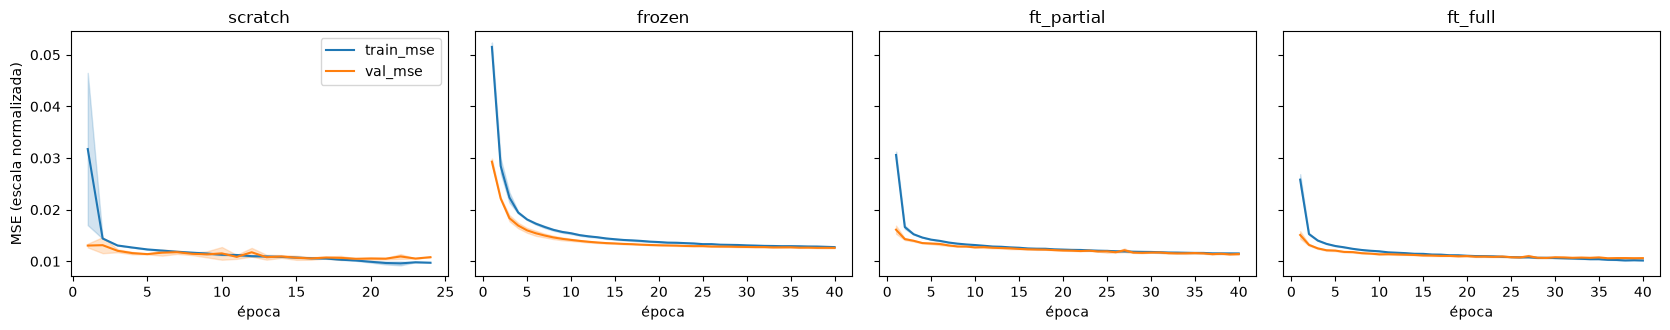

,semilla,mejor_ép,val_mse_mejor,brecha_val-train,|grad|_prim5,|grad|_ult5
regimen,,,,,,
frozen,1.0,39.66667,0.01259,-0.00022,0.03505,0.01579
ft_full,1.0,31.00000,0.01062,0.00005,0.48260,0.31966
ft_partial,1.0,39.00000,0.01132,-0.00018,0.46521,0.30996
scratch,1.0,16.33333,0.01029,-0.00026,0.66515,0.36697


In [13]:
# ── Curvas de entrenamiento/validación: media ± sd entre semillas por régimen ──
fig, ax = plt.subplots(1, len(REGIMENES), figsize=(4.2 * len(REGIMENES), 3.4), sharey=True)
for a, r in zip(ax, REGIMENES):
    L = max(len(x["historia"]) for x in res[r])
    for clave, col in (("train_mse", "tab:blue"), ("val_mse", "tab:orange")):
        M = np.full((len(res[r]), L), np.nan)
        for i, x in enumerate(res[r]): M[i, :len(x["historia"])] = [h[clave] for h in x["historia"]]
        mu, sd = np.nanmean(M, 0), np.nanstd(M, 0)
        a.plot(range(1, L + 1), mu, color=col, label=clave); a.fill_between(range(1, L + 1), mu - sd, mu + sd, color=col, alpha=.2)
    a.set_title(r); a.set_xlabel("época")
ax[0].set_ylabel("MSE (escala normalizada)"); ax[0].legend(); plt.tight_layout()
plt.savefig(OUT / "figuras" / "curvas_regimenes.png", dpi=160); plt.show()

# Diagnóstico numérico: brecha train–val en la mejor época y norma del gradiente
diag = []
for r in REGIMENES:
    for x in res[r]:
        h = x["historia"][x["mejor_epoca"] - 1]
        diag.append({"regimen": r, "semilla": x["semilla"], "mejor_ép": x["mejor_epoca"], "val_mse_mejor": h["val_mse"],
                     "brecha_val-train": h["val_mse"] - h["train_mse"],
                     "|grad|_prim5": np.mean([q["grad_norm"] for q in x["historia"][:5]]),
                     "|grad|_ult5": np.mean([q["grad_norm"] for q in x["historia"][-5:]])})
display(pd.DataFrame(diag).groupby("regimen").mean(numeric_only=True).round(5))

## §7. Auditoría mediante explicabilidad (núcleo de la Entrega final)
Para un Transformer con atención dispersa, la auditoría combina **mapas de atención** con **pruebas de perturbación** que miden qué usa realmente el modelo. La pregunta central es si el STN aprendió dinámica atmosférica o simplemente **copia la última hora de PM2.5** (el atajo de la persistencia).

Modelos auditados: `AUDIT = [(régimen, semilla), …]`; por defecto `scratch` y `ft_full`, semilla 0.

scratch s0: RMSE base 6.040 | sd por muestreo de keys en inferencia = 0.0374 µg/m³
ft_full s0: RMSE base 5.895 | sd por muestreo de keys en inferencia = 0.0083 µg/m³


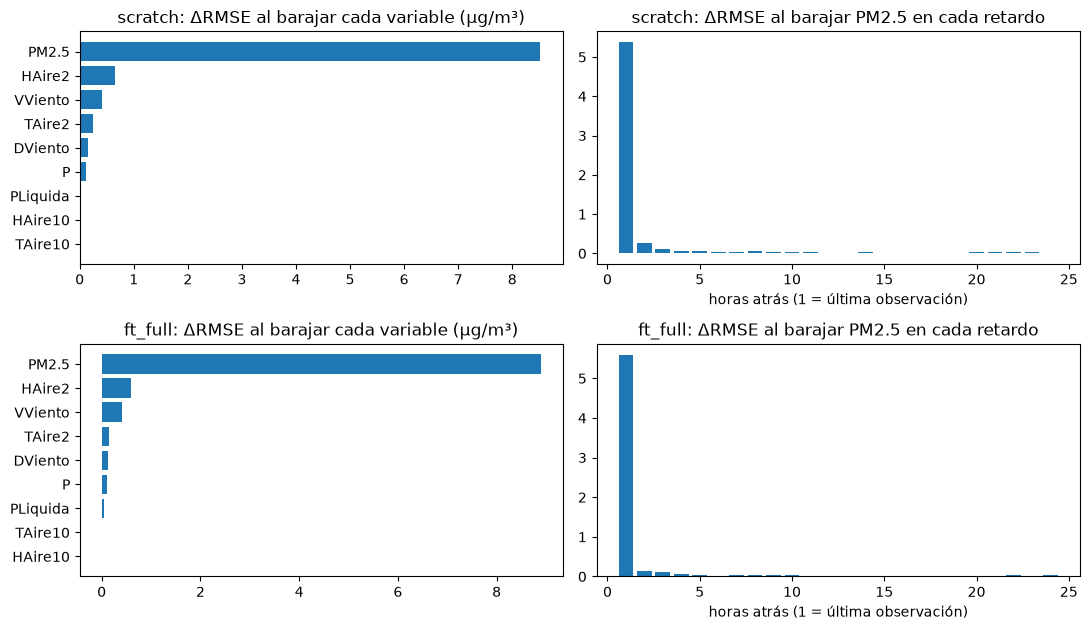

In [14]:
AUDIT = [("scratch", SEMILLAS[0]), ("ft_full", SEMILLAS[0])]
def cargar(r, s):
    m = S.construir_modelo(d_bog.train.shape[1], CFG, PRED)
    m.load_state_dict(torch.load(OUT / "modelos" / f"stn_{r}_s{s}.pt", map_location=DEVICE)); return m.eval()

ENC, DEC = T_bog["test"][0], T_bog["test"][1]
OBS = torch.tensor(d_bog.obs_test, device=DEVICE)
names = d_bog.feature_names; ti = d_bog.target_idx
rng_t = torch.Generator(device="cpu"); rng_t.manual_seed(123)

def rmse_con(model, enc, dec):
    p = d_bog.inverse_target(S.predecir(model, enc, dec, S.fwd_stn))
    return float(np.sqrt(np.mean((p[d_bog.obs_test] - y_test[d_bog.obs_test]) ** 2))), p

def permutar(enc, dec, cols, lags, rep=3):
    # Rompe la relación de (variables, lags) con el objetivo barajando entre ventanas; promedia `rep` barajados.
    outs = []
    for _ in range(rep):
        perm = torch.randperm(len(enc), generator=rng_t).to(DEVICE)
        e, d = enc.clone(), dec.clone()
        for s in lags:
            e[:, s, cols] = enc[perm][:, s, cols]
            r = s - (SEQ - LABEL)
            if r >= 0: d[:, r, cols] = dec[perm][:, r, cols]
        outs.append((e, d))
    return outs

resultados_audit = {}
for r, s in AUDIT:
    m = cargar(r, s); base_rmse, p0 = rmse_con(m, ENC, DEC)
    # (a) importancia por variable (todos los lags) y (b) por retardo (solo PM2.5)
    imp_var = {}
    for j, n in enumerate(names):
        imp_var[n] = np.mean([rmse_con(m, e, d)[0] - base_rmse for e, d in permutar(ENC, DEC, [j], range(SEQ))])
    imp_lag = {}
    for k in range(SEQ):
        imp_lag[SEQ - k] = np.mean([rmse_con(m, e, d)[0] - base_rmse for e, d in permutar(ENC, DEC, [ti], [k])])  # clave: horas atrás (1 = última hora)
    # (c) varianza por muestreo aleatorio de keys en inferencia (ProbAttention es estocástica también en eval)
    reps = np.array([S.predecir(m, ENC, DEC, S.fwd_stn) for _ in range(5)])
    sd_inf = float(reps.std(axis=0).mean() * (d_bog.scaler_max[ti] - d_bog.scaler_min[ti]))   # sd entre repeticiones, en µg/m³
    resultados_audit[(r, s)] = {"rmse_base": base_rmse, "imp_var": imp_var, "imp_lag": imp_lag, "sd_inferencia_ugm3": sd_inf}
    print(f"{r} s{s}: RMSE base {base_rmse:.3f} | sd por muestreo de keys en inferencia = {sd_inf:.4f} µg/m³")

fig, ax = plt.subplots(len(AUDIT), 2, figsize=(11, 3.2 * len(AUDIT)), squeeze=False)
for i, ((r, s), v) in enumerate(resultados_audit.items()):
    ser = pd.Series(v["imp_var"]).sort_values(); ax[i, 0].barh(ser.index, ser.values); ax[i, 0].set_title(f"{r}: ΔRMSE al barajar cada variable (µg/m³)")
    ax[i, 1].bar(list(v["imp_lag"].keys()), list(v["imp_lag"].values())); ax[i, 1].set_title(f"{r}: ΔRMSE al barajar PM2.5 en cada retardo"); ax[i, 1].set_xlabel("horas atrás (1 = última observación)")
plt.tight_layout(); plt.savefig(OUT / "figuras" / "importancia_permutacion.png", dpi=160); plt.show()

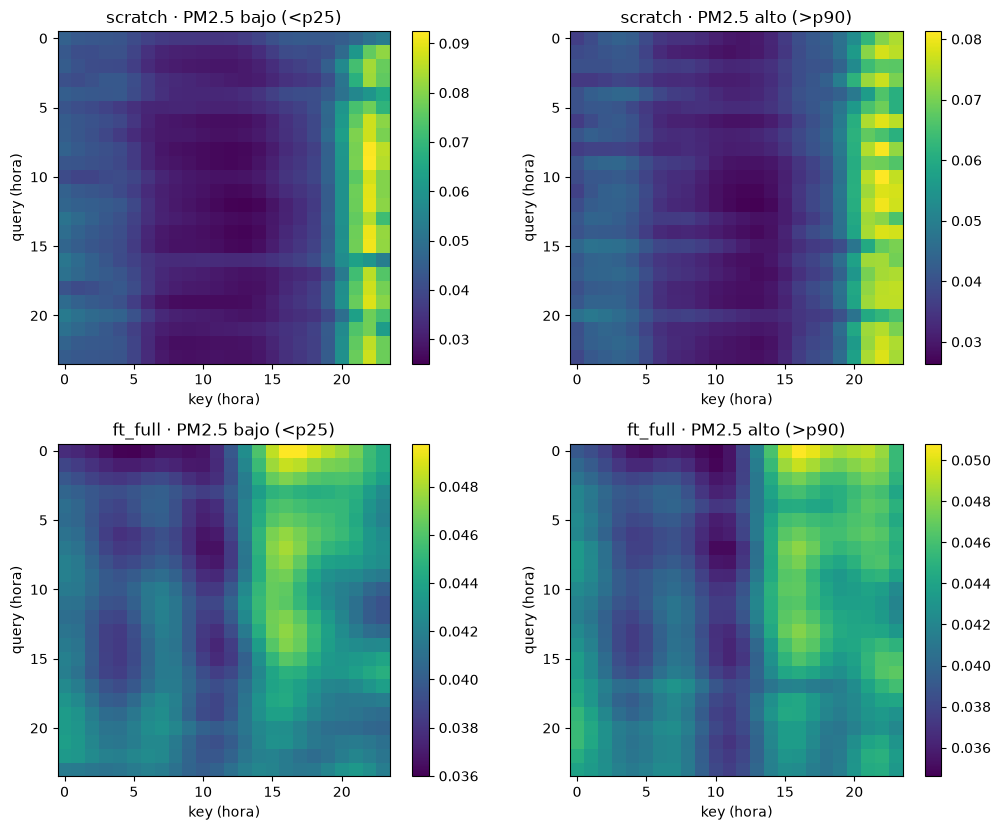

Queries seleccionadas por la atención dispersa: u=20 de L=24 (83%); las demás reciben contexto uniforme.
Atención recibida por la última hora vs promedio (1/L=0.042):


,scratch · PM2.5 bajo (<p25),scratch · PM2.5 alto (>p90),ft_full · PM2.5 bajo (<p25),ft_full · PM2.5 alto (>p90)
última hora,0.0751,0.0713,0.0422,0.0442
últimas 3 h,0.0765,0.0717,0.0426,0.0449
primeras 12 h,0.0366,0.0369,0.0399,0.0395


In [15]:
# ── Mapas de atención (atención dispersa del primer bloque del encoder, rama completa de 24 h) ──
def atencion(model, enc, dec, idx):
    ia = model.encoder.encoders[0].attn_layers[0].attention.inner_attention
    ia.capture = True
    with torch.no_grad(): model(enc[idx], dec[idx])
    ia.capture = False
    a, ind = ia.last_attn, ia.last_index                      # (B,H,u,L), (B,H,u)
    B, H, u, L = a.shape
    A = torch.full((B, H, L, L), 1.0 / L)                      # queries no seleccionadas: contexto = media de V (≈ uniforme)
    A.scatter_(2, ind.unsqueeze(-1).expand(-1, -1, -1, L), a)
    return A.mean(dim=(0, 1)).numpy(), (u, L)

pm_ult = d_bog.inverse_target(W_bog["test"][0][:, -1, ti])
grupos = {"PM2.5 bajo (<p25)": np.where(pm_ult < np.percentile(pm_ult, 25))[0],
          "PM2.5 alto (>p90)": np.where(pm_ult > np.percentile(pm_ult, 90))[0]}
fig, ax = plt.subplots(len(AUDIT), len(grupos), figsize=(5.2 * len(grupos), 4.2 * len(AUDIT)), squeeze=False)
att_col = {}
for i, (r, s) in enumerate(AUDIT):
    m = cargar(r, s)
    for j, (g, ids) in enumerate(grupos.items()):
        A, (u, L) = atencion(m, ENC, DEC, torch.tensor(ids[:512], device=DEVICE))
        im = ax[i, j].imshow(A, cmap="viridis"); ax[i, j].set_title(f"{r} · {g}"); ax[i, j].set_xlabel("key (hora)"); ax[i, j].set_ylabel("query (hora)")
        plt.colorbar(im, ax=ax[i, j], fraction=.046); att_col[(r, g)] = A.mean(axis=0)
plt.tight_layout(); plt.savefig(OUT / "figuras" / "mapas_atencion.png", dpi=160); plt.show()
print(f"Queries seleccionadas por la atención dispersa: u={u} de L={L} ({u/L:.0%}); las demás reciben contexto uniforme.")
print("Atención recibida por la última hora vs promedio (1/L=%.3f):" % (1 / L))
display(pd.DataFrame({f"{k[0]} · {k[1]}": [v[-1], v[-3:].mean(), v[:12].mean()] for k, v in att_col.items()},
                     index=["última hora", "últimas 3 h", "primeras 12 h"]).round(4))

In [16]:
# ── Pruebas de respuesta conocida (contrafactuales) ──
# Se desplaza una variable +1 desv. est. de train en TODOS los pasos y se mide el cambio medio de la predicción (µg/m³).
# Se espera: PM2.5 pasado ↑ ⇒ predicción ↑ ; viento (VViento) ↑ ⇒ ↓ ; lluvia (PLiquida) ↑ ⇒ ↓ (lavado atmosférico).
def contrafactual(model, var, delta_real, solo_ultimo=False):
    j = names.index(var); rg = d_bog.scaler_max[j] - d_bog.scaler_min[j]
    e, d = ENC.clone(), DEC.clone()
    if solo_ultimo: e[:, -1, j] += delta_real / rg; d[:, LABEL - 1, j] += delta_real / rg
    else: e[:, :, j] += delta_real / rg; d[:, :LABEL, j] += delta_real / rg
    p1 = d_bog.inverse_target(S.predecir(model, e, d, S.fwd_stn)); p0 = d_bog.inverse_target(S.predecir(model, ENC, DEC, S.fwd_stn))
    return float((p1 - p0)[d_bog.obs_test].mean())

filas = []
for r, s in AUDIT:
    m = cargar(r, s)
    f = {"modelo": f"{r} s{s}", "PM2.5 última hora +10 µg → Δpred": contrafactual(m, "PM2.5", 10.0, solo_ultimo=True),
         "(persistencia: +10.0)": 10.0}
    for v in names:
        if v != "PM2.5": f[f"{v} +1σ → Δpred"] = contrafactual(m, v, float(d_bog.train_std[names.index(v)]))
    filas.append(f)
cf = pd.DataFrame(filas).set_index("modelo").T.round(3); display(cf)

modelo,scratch s0,ft_full s0
PM2.5 última hora +10 µg → Δpred,5.005,5.267
(persistencia: +10.0),10.000,10.000
TAire2 +1σ → Δpred,-1.058,-0.922
TAire10 +1σ → Δpred,-0.149,-0.161
HAire2 +1σ → Δpred,-0.472,-0.211
HAire10 +1σ → Δpred,-0.064,-0.184
P +1σ → Δpred,-0.089,-0.092
DViento +1σ → Δpred,0.366,0.136
VViento +1σ → Δpred,-0.089,-0.403
PLiquida +1σ → Δpred,-0.453,-0.758


In [17]:
# ── Comportamiento fuera del dominio: ventanas cuyo PM2.5 de entrada estaba mayormente IMPUTADO ──
miss = d_bog.miss_test_ctx
frac_imp = np.array([miss[i:i + SEQ].mean() for i in range(len(d_bog.obs_test))])
bins = pd.cut(frac_imp, [-.01, 0, .25, .75, 1.0], labels=["0%", "(0,25%]", "(25,75%]", ">75%"])
filas = []
for nombre in ["persistencia", "stn_scratch", "stn_ft_full", "lstm"]:
    z = np.load(OUT / (nombre + "_s0_preds.npz")); e = (z["pred_test"] - z["true_test"])
    d = pd.DataFrame({"e2": e ** 2, "bin": np.asarray(bins.astype(str)), "obs": z["obs_test"]}); d = d[d.obs]
    filas.append(d.groupby("bin")["e2"].agg(lambda x: np.sqrt(x.mean())).rename(nombre))
filas.append(d.groupby("bin").size().rename("n_horas"))
display(pd.concat(filas, axis=1).round(3))
print("RMSE por fracción de la ventana de entrada que era PM2.5 imputado (relleno causal).")

,persistencia,stn_scratch,stn_ft_full,lstm,n_horas
bin,,,,,
"(0,25%]",7.421,6.536,6.375,6.461,1311
"(25,75%]",7.555,6.606,6.389,6.254,80
0%,6.693,5.938,5.790,5.912,7142
>75%,12.476,6.917,8.314,6.609,14


RMSE por fracción de la ventana de entrada que era PM2.5 imputado (relleno causal).


## §8. Análisis de fallas y calibración
Se usa el **promedio entre semillas del error por hora** (para no depender de una inicialización) y se compara contra la persistencia. Calibración: intervalos de **conformal dividido** con los residuos de validación (sin tocar test), cuya cobertura empírica se mide en test.


── Error por nivel ──


,n,RMSE_STN,RMSE_pers,sesgo_STN
nivel,,,,
≤15,3397,4.081,4.900,1.815
15–25,2534,4.771,6.325,0.137
25–37,1677,5.750,7.942,-2.389
>37,939,12.348,10.833,-9.302



── Error por salto ──


,n,RMSE_STN,RMSE_pers,sesgo_STN
salto,,,,
Q1 estable,2137,3.457,0.883,-0.010
Q2,2137,3.907,2.517,-0.207
Q3,2136,4.989,4.895,-0.706
Q4 cambio brusco,2137,9.711,12.474,-1.992



── Error por hora ──


,n,RMSE_STN,RMSE_pers,sesgo_STN
hora,,,,
0,359,6.314,6.190,-0.259
1,354,6.307,6.875,-2.036
2,358,5.594,7.768,1.010
3,359,4.708,5.337,-0.147
4,358,5.261,5.461,-0.039
5,360,5.443,6.197,-0.216
6,361,7.368,8.471,-1.726
7,360,8.145,8.040,-1.872
8,356,8.215,8.171,0.134



── Error por mes ──


,n,RMSE_STN,RMSE_pers,sesgo_STN
mes,,,,
1,742,7.201,7.933,-1.254
2,693,6.296,6.968,-1.227
3,739,7.802,7.661,-3.521
4,716,7.122,7.711,-2.104
5,735,5.031,6.415,-0.030
6,713,5.278,6.475,0.308
7,669,3.895,4.569,0.427
8,739,5.365,6.313,-0.552
9,680,6.420,6.845,-0.965


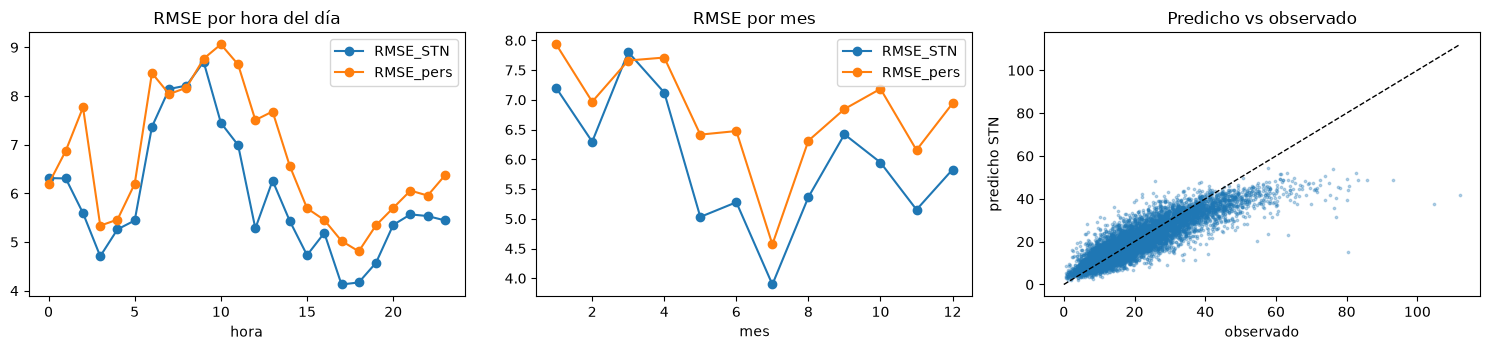


Peores 10 horas del STN (error absoluto):


,true,stn,pers,e_stn,e_pers
fecha_hora,,,,,
2024-03-23 00:00:00,112.099998,41.799999,54.200001,-70.300003,-57.900002
2024-04-01 09:00:00,104.599998,37.700001,47.200001,-66.900002,-57.400002
2024-01-09 11:00:00,80.400002,15.300000,15.100000,-65.099998,-65.300003
2024-09-04 16:00:00,77.099998,31.500000,35.099998,-45.599998,-42.000000
2024-09-04 10:00:00,93.000000,48.799999,74.000000,-44.200001,-19.000000
2024-06-14 06:00:00,76.400002,35.700001,32.099998,-40.700001,-44.299999
2024-01-26 11:00:00,80.000000,39.599998,71.599998,-40.400002,-8.400000
2024-12-31 22:00:00,63.400002,23.200001,23.299999,-40.200001,-40.099998
2024-01-25 08:00:00,85.699997,48.900002,77.500000,-36.799999,-8.200000


In [18]:
def cargar_err(nombre, sem):
    zs = [np.load(OUT / f"{nombre}_s{s}_preds.npz") for s in sem]
    pred = np.mean([z["pred_test"] for z in zs], axis=0); true = zs[0]["true_test"]; obs = zs[0]["obs_test"]
    return pred, true, obs

idx_t = d_bog.test_index
pred_s, true_t, obs_t = cargar_err("stn_scratch", SEMILLAS)
pred_f, _, _ = cargar_err("stn_ft_full", SEMILLAS)
pred_p, _, _ = cargar_err("persistencia", [0])
D = pd.DataFrame({"true": true_t, "stn": pred_s, "stn_tl": pred_f, "pers": pred_p}, index=idx_t)[obs_t]
for c in ("stn", "stn_tl", "pers"): D[f"e_{c}"] = D[c] - D["true"]
D["hora"] = D.index.hour; D["mes"] = D.index.month
D["delta_real"] = (D["true"] - D["pers"]).abs()                      # cuánto cambió respecto a la hora previa
UMBRAL = 37.0                                                         # µg/m³ (ajustar al umbral normativo diario que citen en el informe)
D["nivel"] = pd.cut(D["true"], [-1, 15, 25, UMBRAL, 1e9], labels=["≤15", "15–25", f"25–{UMBRAL:g}", f">{UMBRAL:g}"])
D["salto"] = pd.qcut(D["delta_real"].rank(method="first"), 4, labels=["Q1 estable", "Q2", "Q3", "Q4 cambio brusco"])
rm = lambda e: np.sqrt(np.mean(e ** 2))
def tabla(col):
    g = D.groupby(col, observed=True)
    return pd.DataFrame({"n": g.size(), "RMSE_STN": g["e_stn"].apply(rm), "RMSE_pers": g["e_pers"].apply(rm),
                         "sesgo_STN": g["e_stn"].mean()}).round(3)
for c in ("nivel", "salto", "hora", "mes"):
    print(f"\n── Error por {c} ──"); display(tabla(c))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
tabla("hora")[["RMSE_STN", "RMSE_pers"]].plot(ax=ax[0], marker="o", title="RMSE por hora del día")
tabla("mes")[["RMSE_STN", "RMSE_pers"]].plot(ax=ax[1], marker="o", title="RMSE por mes")
ax[2].scatter(D["true"], D["stn"], s=3, alpha=.3); lim = [0, D["true"].max()]; ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xlabel("observado"); ax[2].set_ylabel("predicho STN"); ax[2].set_title("Predicho vs observado")
plt.tight_layout(); plt.savefig(OUT / "figuras" / "fallas.png", dpi=160); plt.show()

print("\nPeores 10 horas del STN (error absoluto):")
display(D.assign(abs_e=D.e_stn.abs()).nlargest(10, "abs_e")[["true", "stn", "pers", "e_stn", "e_pers"]].round(1))

In [19]:
# ── Calibración: intervalos conformales (residuos de validación) y cobertura en test ──
def cobertura(prefijo, sem, niveles=(0.8, 0.9)):
    out = []
    for s in sem:
        z = np.load(OUT / f"{prefijo}_s{s}_preds.npz")
        rv = np.abs(z["pred_val"] - z["true_val"])[z["obs_val"]]
        et = np.abs(z["pred_test"] - z["true_test"])[z["obs_test"]]; yt = z["true_test"][z["obs_test"]]
        for nv in niveles:
            q = np.quantile(rv, nv)
            cov = (et <= q).mean(); cov_pico = (et[yt > UMBRAL] <= q).mean()
            out.append({"modelo": prefijo, "semilla": s, "nominal": nv, "cobertura": cov, "cobertura_>umbral": cov_pico, "semiancho_µg": q})
    return pd.DataFrame(out)
cal = pd.concat([cobertura("stn_scratch", SEMILLAS), cobertura("stn_ft_full", SEMILLAS)])
display(cal.groupby(["modelo", "nominal"]).mean(numeric_only=True).drop(columns="semilla").round(3))
print("Cobertura < nominal en picos (>umbral) = el intervalo único subestima la incertidumbre justo donde más importa.")

cobertura  cobertura_>umbral  semiancho_µg
modelo      nominal                                            
stn_ft_full 0.8          0.764              0.415         5.915
            0.9          0.872              0.569         8.104
stn_scratch 0.8          0.754              0.344         5.831
            0.9          0.859              0.493         7.949

Cobertura < nominal en picos (>umbral) = el intervalo único subestima la incertidumbre justo donde más importa.


## §9. Tabla de evidencia para el dictamen (¿se justificaba la profundidad?)

In [20]:
ev = resumen.loc[["persistencia", "ridge", "rf", "LSTM", "STN-scratch", "STN-frozen", "STN-ft_partial", "STN-ft_full"],
                 ["RMSE_media", "RMSE_sd", "MAE_media", "R2_media", "seg_entren", "seg_infer"]].copy()
ev["params_entrenables"] = [0, Xtr.shape[1] + 1, np.nan,
                            int(np.mean([x["info"]["params_entrenables"] for x in res_lstm])),
                            *[res[r][0]["info"]["params_entrenables"] for r in REGIMENES]]
ev["ΔRMSE vs persistencia (%)"] = 100 * (ev["RMSE_media"] - ev.loc["persistencia", "RMSE_media"]) / ev.loc["persistencia", "RMSE_media"]
display(ev.round(3))
print(f"n de evaluación común: {int(d_bog.obs_test.sum())} horas con PM2.5 observado (2024).")

,RMSE_media,RMSE_sd,MAE_media,R2_media,seg_entren,seg_infer,params_entrenables,ΔRMSE vs persistencia (%)
modelo,,,,,,,,
persistencia,6.831,NaN,4.812,0.704,0.000,0.000,0.0,0.000
ridge,5.924,NaN,4.239,0.777,0.265,0.005,217.0,-13.278
rf,6.967,NaN,4.728,0.692,16.517,0.116,NaN,1.979
LSTM,6.035,0.034,4.286,0.769,54.133,0.016,52545.0,-11.654
STN-scratch,6.088,0.044,4.269,0.765,515.133,0.361,1216385.0,-10.881
STN-frozen,6.076,0.042,4.358,0.766,788.600,0.407,6912.0,-11.059
STN-ft_partial,5.989,0.089,4.213,0.772,838.433,0.504,404865.0,-12.331
STN-ft_full,5.921,0.025,4.181,0.777,910.133,0.405,1216385.0,-13.328


n de evaluación común: 8547 horas con PM2.5 observado (2024).


## §10. Exportar resumen para el informe

In [21]:
resumen_json = {
  "protocolo": {"n_eval": int(d_bog.obs_test.sum()), "horas_2024": int(len(d_bog.obs_test)), "primeras24_observadas": primeras24,
                "semillas": SEMILLAS, "cfg": CFG, "batch": BATCH, "lr_nuevo": LR_NUEVO, "lr_cuerpo": LR_CUERPO,
                "epocas_max": EPOCAS, "paciencia": PACIENCIA},
  "beijing128": {k: res_bj[k] for k in ("RMSE", "MAE", "R2", "n", "mejor_epoca", "epocas", "seg_entrenamiento")},
  "beijing_persistencia": m_pers_bj,
  "transferencia": {r: {k: v for k, v in info_r[r].items() if k != "no_cargados"} for r in REGIMENES},
  "no_cargados": info_r["frozen"]["no_cargados"],
  "resumen_modelos": json.loads(resumen.to_json(orient="index")),
  "pareado": json.loads(tabla_par.to_json(orient="records")),
  "diagnostico_curvas": json.loads(pd.DataFrame(diag).groupby("regimen").mean(numeric_only=True).to_json(orient="index")),
  "auditoria": {f"{r}_s{s}": {"rmse_base": v["rmse_base"], "imp_var": v["imp_var"], "imp_lag": {str(k): x for k, x in v["imp_lag"].items()},
                              "sd_inferencia_ugm3": v["sd_inferencia_ugm3"]} for (r, s), v in resultados_audit.items()},
  "contrafactuales": json.loads(cf.to_json()),
  "atencion_ultima_hora": {f"{k[0]}|{k[1]}": float(v[-1]) for k, v in att_col.items()},
  "fallas_nivel": json.loads(tabla("nivel").to_json(orient="index")),
  "fallas_salto": json.loads(tabla("salto").to_json(orient="index")),
  "calibracion": json.loads(cal.groupby(["modelo", "nominal"]).mean(numeric_only=True).drop(columns="semilla").reset_index().to_json(orient="records")),
}
(OUT / "resumen_entrega_final.json").write_text(json.dumps(resumen_json, indent=1, ensure_ascii=False, default=float))
print("Listo → resultados_final/resumen_entrega_final.json  (compártelo junto con la carpeta resultados_final/figuras)")

Listo → resultados_final/resumen_entrega_final.json  (compártelo junto con la carpeta resultados_final/figuras)
